# 2 — Learned deviations (without PDHG)

Learned scheme against the zero-deviation baseline and the random control, on
one held-out Mayo slice. Run `main.py` first: it trains the model and writes
the checkpoint loaded below.

Figures are saved as PDF in `plots/` (prefix `2_`).

In [1]:
import torch

from utils.experiments import (build_test_instance, reference_solution, run_fbs,
                               random_direction, objective_gap, time_table, load_model)
from utils.plots import apply_paper_style, plot_curves, show_images

apply_paper_style()

In [2]:
# --- configuration (must match main.py) ---------------------------------------
SIZE = 512
N_ANGLES = 180
NOISE_LEVEL = 0.05
GAMMA = 2
PRIMAL_STEP = 1            # primal step tau (see main.py)

TEST_PATIENT = "L014"      # never used for training or validation
TEST_SLICE = 0
MAYO_CACHE_DIR = "./data/mayo_cache_512"
CKPT = "model_512.pt"    # written by main.py
# written by main.py with USE_SAFEGUARD = False; if the file is missing, the
# ablation applies the safeguarded model without its safeguard instead
CKPT_NOSAFE = "model_512_nosafe.pt"

T_TRAIN = 10               # unrolling horizon used in training
T_LONG = 100          # length of the convergence curves
T_REF = 6000               # length of the run that defines F* (cached in results/)

In [3]:
inst = build_test_instance(SIZE, N_ANGLES, NOISE_LEVEL, GAMMA, TEST_PATIENT, TEST_SLICE,
                           MAYO_CACHE_DIR, primal_step=PRIMAL_STEP)
ref = reference_solution(inst, T_REF)
print(f"F* = {ref['f_star']:.4f}, PSNR of the TGV2 solution = {ref['psnr']:.2f} dB")

/home/beille/venv/lib/python3.12/site-packages/torch/cuda/__init__.py:174: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:109.)
  return torch._C._cuda_getDeviceCount() > 0
/home/beille/venv/lib/python3.12/site-packages/odl/tomo/backends/astra_cpu.py:318: RuntimeWarning: The 'astra_cpu' backend may be too slow for volumes of this size. Consider using 'astra_cuda' if your machine has an Nvidia GPU.
  warnings.warn(


F* = 8.0576, PSNR of the TGV2 solution = 26.41 dB


In [4]:
import os

model, ckpt = load_model(CKPT, inst, T=T_TRAIN)
model_nosafe = (load_model(CKPT_NOSAFE, inst, T=T_TRAIN, use_safeguard=False)[0]
                if os.path.exists(CKPT_NOSAFE) else model)

## Training curves

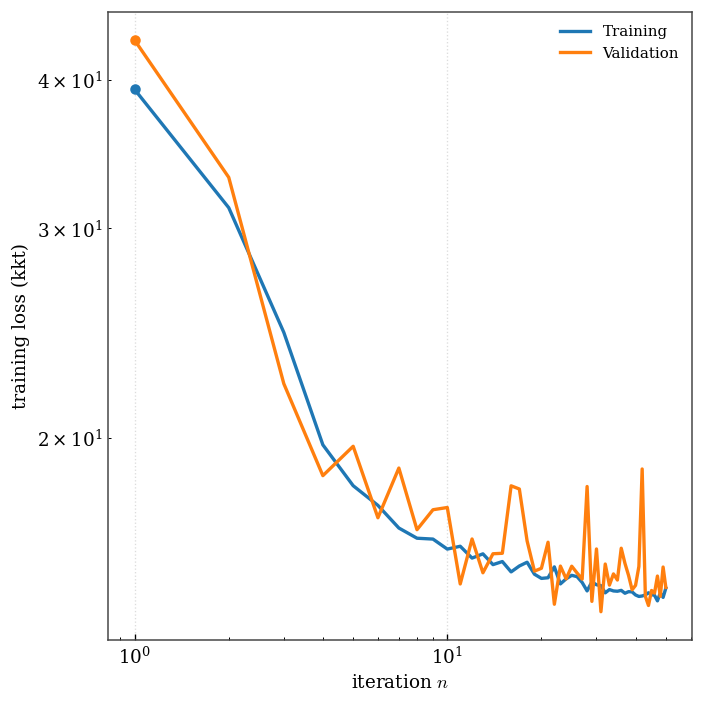

In [5]:
plot_curves({"Training": ckpt["train_loss_history"], "Validation": ckpt["val_loss_history"]},
            f"training loss ({ckpt.get('loss', 'kkt')})", "2_training", show=True)

## Runs

In [6]:
results = {
    "Zero deviation": run_fbs(inst, T_LONG, snapshots=(T_TRAIN,)),
    "Learned": run_fbs(inst, T_LONG, model, snapshots=(T_TRAIN,)),
    "Random": run_fbs(inst, T_LONG, random_direction(seed=0), snapshots=(T_TRAIN,)),
}
no_safeguard = run_fbs(inst, T_LONG, model_nosafe, use_safeguard=False, restart=False,
                       snapshots=(T_TRAIN,))

  0%|          | 0/100 [00:00<?, ?it/s]

## Convergence

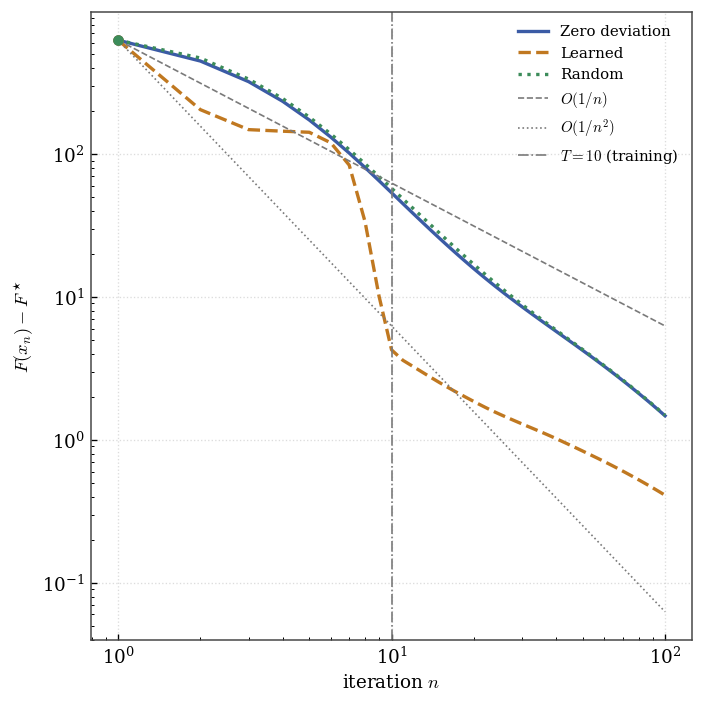

In [7]:
gaps = {label: objective_gap(r, ref["f_star"]) for label, r in results.items()}
plot_curves(gaps, r"$F(x_n) - F^\star$", "2_objective_gap", slopes=True, horizon=T_TRAIN, iteration_start=0, show=True)

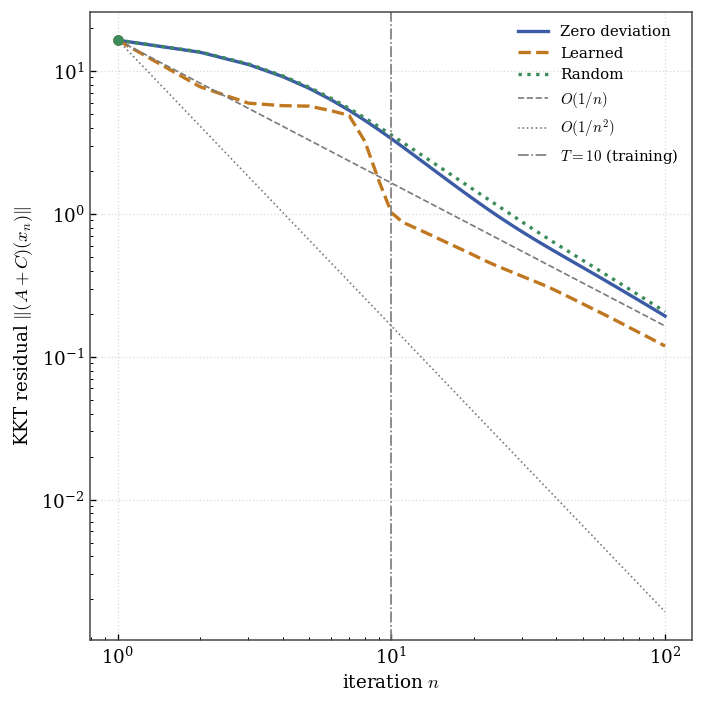

In [8]:
plot_curves({label: r["kkt"] for label, r in results.items() if "kkt" in r},
            r"KKT residual $\|(A + C)(x_n)\|$", "2_kkt", slopes=True, horizon=T_TRAIN, show=True)

## Safeguard ablation

The same trained network, with its output applied directly instead of being rescaled by the safeguard.

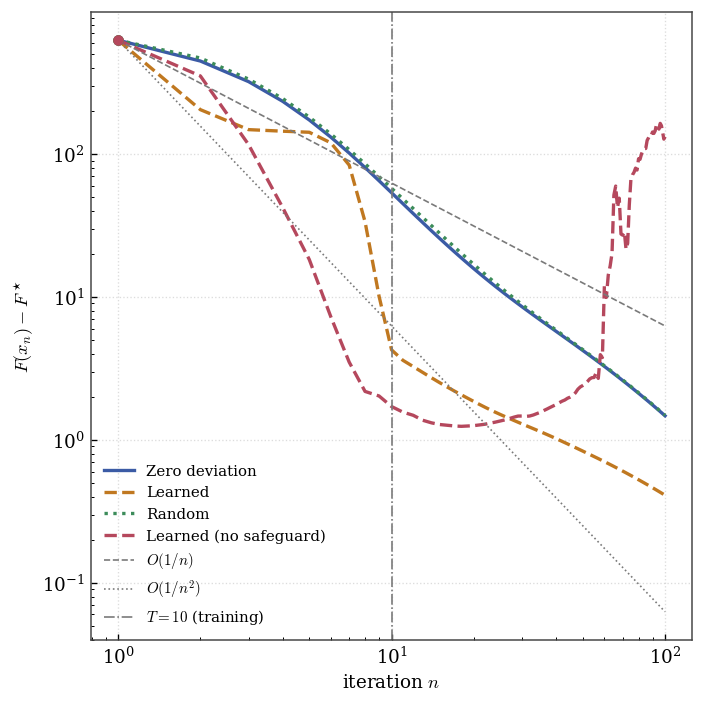

In [9]:
ablation = dict(results, **{"Learned (no safeguard)": no_safeguard})
plot_curves({label: objective_gap(r, ref["f_star"]) for label, r in ablation.items()},
            r"$F(x_n) - F^\star$", "2_safeguard_ablation", slopes=True, horizon=T_TRAIN, iteration_start=0, show=True)

## PSNR

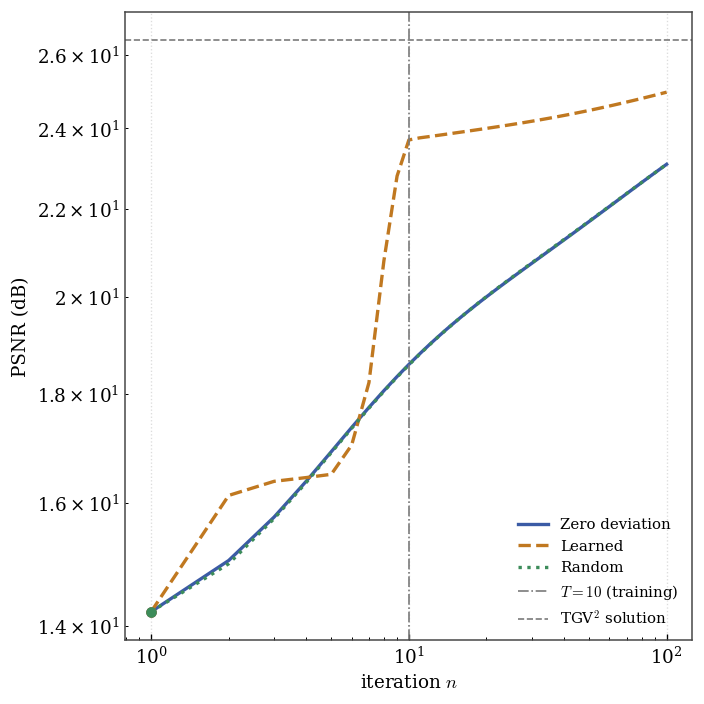

In [10]:
plot_curves({label: r["psnr"] for label, r in results.items()}, "PSNR (dB)", "2_psnr",
            loglog=True, horizon=T_TRAIN, hline=(ref["psnr"], r"TGV$^2$ solution"), iteration_start=0, show=True)

## Reconstructions

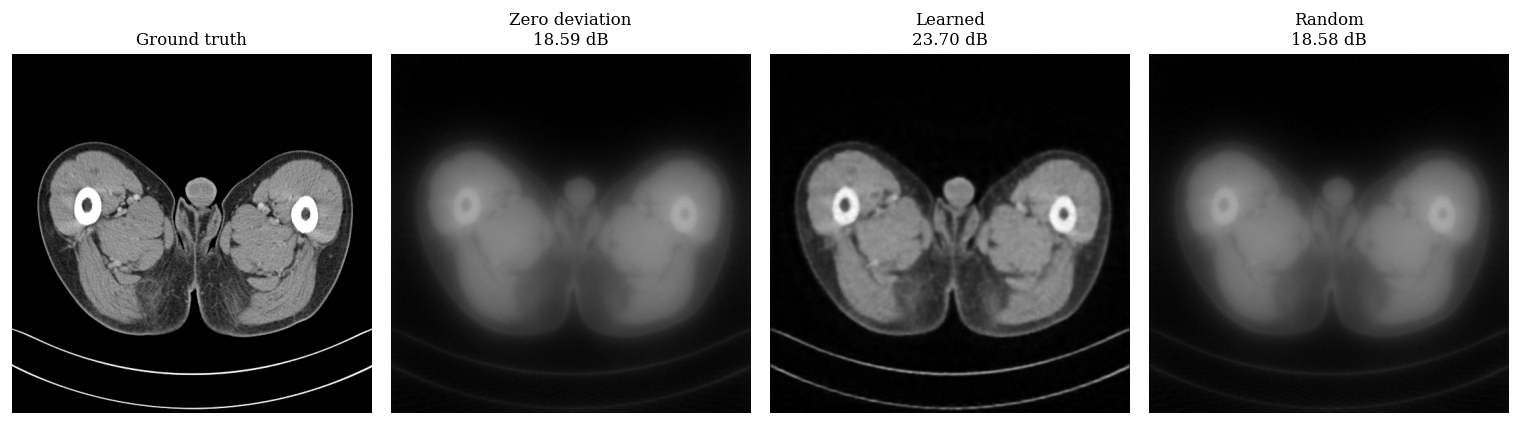

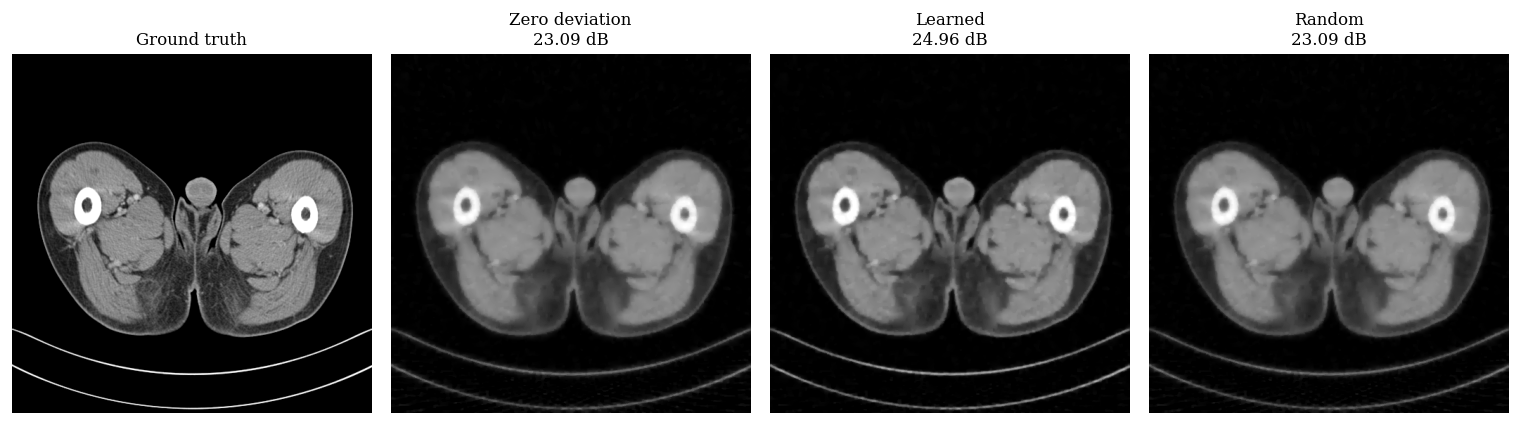

In [11]:
def gallery(n):
    """Ground truth and the reconstruction of every method after n iterations."""
    images = {"Ground truth": inst["clean"]}
    for label, r in results.items():
        images[f"{label}\n{r['psnr'][n]:.2f} dB"] = r["images"][n]
    return images

show_images(gallery(T_TRAIN), "2_reconstructions_{}_iterations".format(T_TRAIN), show=True)
show_images(gallery(T_LONG), "2_reconstructions_{}_iterations".format(T_LONG), show=True)

### Gradient flow

The dashed streamlines show the spatial gradient `grad(u)` of each reconstruction.

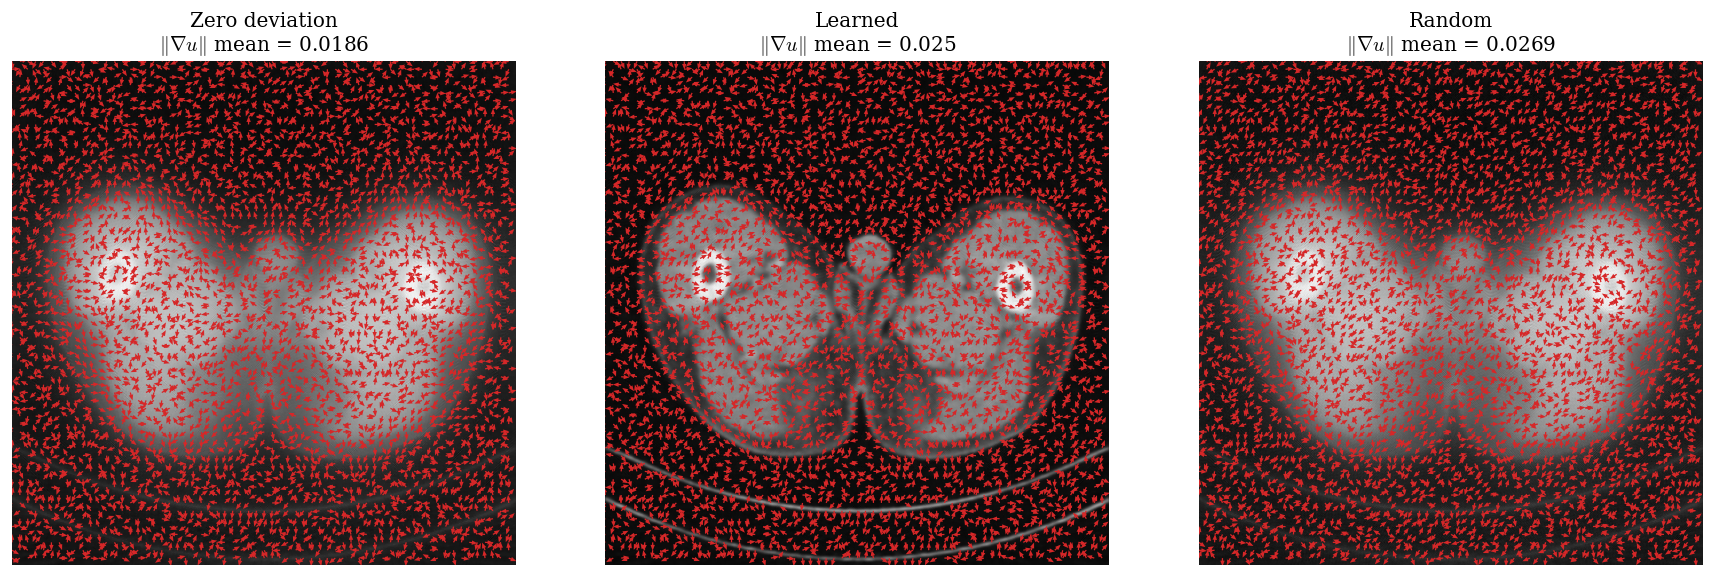

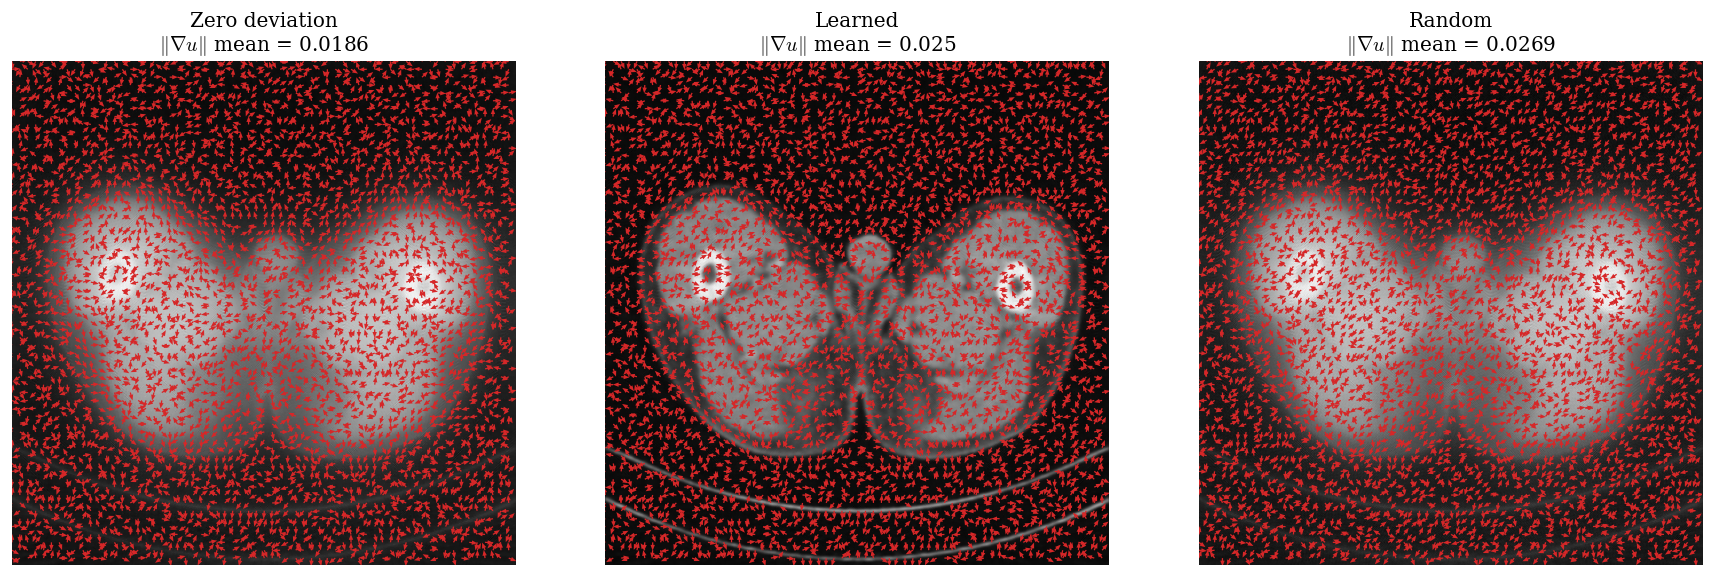

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

iteration = T_TRAIN
methods = list(results)
fig, axes = plt.subplots(1, len(methods), figsize=(5.0 * len(methods), 4.8), squeeze=False)

for ax, label in zip(axes[0], methods):
    u = results[label]["images"][iteration].to(inst["device"])
    gradient = inst["setup"]["grad"](u)[0].detach().cpu().numpy()
    image = u[0, 0].detach().cpu().numpy()
    gy, gx = gradient[0], gradient[1]
    step = 8
    y, x = np.mgrid[0:SIZE:step, 0:SIZE:step]
    gx_plot, gy_plot = gx[::step, ::step], -gy[::step, ::step]
    magnitude = np.hypot(gx_plot, gy_plot)
    gx_plot /= np.maximum(magnitude, 1e-12)
    gy_plot /= np.maximum(magnitude, 1e-12)
    ax.imshow(image, cmap="gray", origin="upper")
    ax.quiver(x, y, gx_plot, gy_plot, color="tab:red", angles="xy",
              scale_units="xy", scale=0.12, width=0.0025,
              headwidth=3.5, headlength=4.5)
    ax.set_title(label + "\n" + rf"$\|\nabla u\|$ mean = {np.hypot(gx, gy).mean():.3g}")
    ax.set_xlim(0, SIZE - 1)
    ax.set_ylim(SIZE - 1, 0)
    ax.set_axis_off()

plt.tight_layout()
plt.savefig("plots/2_gradient_flow.png", dpi=200, bbox_inches="tight")
display(fig)
plt.show()

## Time comparison

Time per iteration is measured on a separate short run without any monitoring
(no KKT residual, objective or PSNR computed). The table is also written as
LaTeX in `plots/`.

In [ ]:
f_star = ref["f_star"]

time_table(results, f_star, name="2_time_comparison")

,Time / iteration (ms),F-F* after 10 it
Method,,
Zero deviation,547,53.62
Learned,809,4.26
Random,851,57.65
